# Table I: Speedup for Methods 1–6 After Including Classifier Operations

This notebook first establishes the operation-count baseline and then measures controlled CPU inference time. The six rows always appear in the following order:

1. `1.BOI_2SSCA_FFTx4_CC11x15_CAP8_latency.ipynb` — CC-trained CAP
2. `2.Snoap2024_CPU_GPU_latency.ipynb` — I/Q–BOI–USP
3. `3.QPSKlike_CC_NN_CPU_GPU_latency.ipynb`, corresponding to Full Eight-Class FFT–CC–CAP in Table I
4. `4.LR55_only_inference_time.ipynb`, corresponding to Direct Eight-Class FFT–LR in Table I
5. `5.LR55_CCCAP_CPU_GPU_end_to_end_latency.ipynb` — Hierarchical FFT–LR/CC–CAP
6. `FullyOnline-Inference-LR55-CAPNetLite-2018train20.ipynb` — Hierarchical FFT–LR/CC–CAPNetLite

Constraints: the front-end, CC, routing probability, and Blind-Processing Operation Count from the original Table I are unchanged, and there are no simplified/original variants. Methods 5 and 6 have identical FFT–LR/CC processing and differ only in the fine-classifier architecture. Classifier computation uses the same **MAC convention** implied by `55×8=440` and `55×5=275`: one multiply-accumulate is counted as one operation. Convolution and fully connected MACs are counted; activation, BN, pooling, softmax, and argmax are excluded from this approximation.

In [1]:
import math
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

N = 32768
N_PRIME = 64
P = 7
K = 18
LOG2_N = math.log2(N)

# The five published Blind-Processing Operation Counts plus Method 6, which shares Method 5's blind route.
table1_blind_ops = np.array([
    62_095_360,
    2_228_224,
    10_813_440,
    1_737_144,
    6_275_347,
    6_275_347,
], dtype=np.int64)

# Reproduce the paper values; Methods 5 and 6 are 50% direct + 50% refined.
cc_processing = int(P * N + K * N * LOG2_N)
front_1 = int(N * N_PRIME * (math.log2(N_PRIME) + LOG2_N + 4) + 3 * N + N * LOG2_N)
front_2 = int(8 * N + 4 * N * LOG2_N)
front_fft3 = int(8 * N + 3 * N * LOG2_N)
direct_4 = front_fft3 + 440
direct_5 = front_fft3 + 275
refined_5 = front_fft3 + 275 + cc_processing
formula_check = np.array([
    front_1 + cc_processing,
    front_2,
    front_fft3 + cc_processing,
    direct_4,
    int(round(0.5 * direct_5 + 0.5 * refined_5)),
    int(round(0.5 * direct_5 + 0.5 * refined_5)),
], dtype=np.int64)
assert np.array_equal(formula_check, table1_blind_ops), (formula_check, table1_blind_ops)

original_speedup = table1_blind_ops[0] / table1_blind_ops
display(pd.DataFrame({
    'method': [1, 2, 3, 4, 5, 6],
    'Table_I_blind_ops': table1_blind_ops,
    'Table_I_speedup': original_speedup,
}).style.format({'Table_I_blind_ops': '{:,.0f}', 'Table_I_speedup': '{:.2f}×'}))

,method,Table_I_blind_ops,Table_I_speedup
0,1,"62,095,360",1.00×
1,2,"2,228,224",27.87×
2,3,"10,813,440",5.74×
3,4,"1,737,144",35.75×
4,5,"6,275,347",9.90×
5,6,"6,275,347",9.90×


In [2]:
# Compute MACs from the classifier layer dimensions used by the six methods.
def conv2d_macs(h_out, w_out, cin, cout, kh, kw):
    return int(h_out * w_out * cin * cout * kh * kw)

def conv1d_macs(length_out, cin, cout, kernel):
    return int(length_out * cin * cout * kernel)

def linear_macs(inputs, outputs):
    return int(inputs * outputs)

def cap8_macs():
    # Paper CAP8: shared Conv 1->56; 8 branches: 56->56->72->FC7->1.
    shared = conv2d_macs(11, 8, 1, 56, 6, 4)
    branch = (
        conv2d_macs(11, 4, 56, 56, 4, 4)
        + conv2d_macs(11, 2, 56, 72, 4, 6)
        + linear_macs(11 * 2 * 72, 7)
        + linear_macs(7, 1)
    )
    return shared + 8 * branch

def qpsklike_cap4_macs():
    # Fine classifier for the hierarchical method: shared=72; 4 branches: 72->72->96->FC12->1.
    shared = conv2d_macs(11, 8, 1, 72, 6, 4)
    branch = (
        conv2d_macs(11, 4, 72, 72, 4, 4)
        + conv2d_macs(11, 2, 72, 96, 4, 6)
        + linear_macs(11 * 2 * 96, 12)
        + linear_macs(12, 1)
    )
    return shared + 4 * branch

def capnetlite_macs():
    # CAPNetLite input [1,11,15]: stem; two c32 residual convs; stride-(1,2) down; two c64 residual convs; FC4.
    stem = conv2d_macs(11, 15, 1, 32, 3, 3)
    block1 = 2 * conv2d_macs(11, 15, 32, 32, 3, 3)
    down = conv2d_macs(11, 8, 32, 64, 3, 3)
    block2 = 2 * conv2d_macs(11, 8, 64, 64, 3, 3)
    head = linear_macs(64, 4)
    return stem + block1 + down + block2 + head

def snoap2024_cnn_macs():
    # Ten CNN branches; channels 16/24/32/48/64/96, kernel=23, halving length after the first five layers.
    branch_input_channels = (2, 1, 2, 1, 2, 2, 1, 2, 1, 2)
    total = 0
    for first_cin in branch_input_channels:
        length, cin = N, first_cin
        for cout in (16, 24, 32, 48, 64):
            total += conv1d_macs(length, cin, cout, 23)
            length //= 2
            cin = cout
        total += conv1d_macs(length, cin, 96, 23)
        total += linear_macs(96, 8)
    total += linear_macs(10 * 8, 8)
    return total

CAP8_MACS = cap8_macs()
SNOAP_CNN_MACS = snoap2024_cnn_macs()
CAP4_MACS = qpsklike_cap4_macs()
CAPNETLITE_MACS = capnetlite_macs()
LR8_MACS = 55 * 8
LR5_MACS = 55 * 5

display(Markdown('### Classifier architectures and MAC derivation'))
display(Markdown(
    '`Conv2D MACs = H_out × W_out × C_in × C_out × K_h × K_w`; '
    '`Conv1D MACs = L_out × C_in × C_out × K`; `FC MACs = inputs × outputs`. '
    'The table applies these rules layer by layer and sums all shared layers, branches, and routing probabilities.'
))
architecture_macs = pd.DataFrame([
    {
        'method': '1',
        'classifier_architecture': 'CAP8: shared 1→56; 8×(56→56→72→FC7→1)',
        'compact_MAC_calculation': '118,272 + 8×(2,207,744 + 2,128,896 + 11,088 + 7)',
        'original_blind_ops': table1_blind_ops[0],
        'classifier_MACs_total': CAP8_MACS,
    },
    {
        'method': '2',
        'classifier_architecture': '10 CNN branches: 16/24/32/48/64/96, k=23; FC8; final FC8',
        'compact_MAC_calculation': 'Σc0∈[2,1,2,1,2,2,1,2,1,2] [32768×c0×16×23 + 16384×16×24×23 + 8192×24×32×23 + 4096×32×48×23 + 2048×48×64×23 + 1024×64×96×23 + 96×8] + 80×8',
        'original_blind_ops': table1_blind_ops[1],
        'classifier_MACs_total': SNOAP_CNN_MACS,
    },
    {
        'method': '3',
        'classifier_architecture': 'CAP8: shared 1→56; 8×(56→56→72→FC7→1)',
        'compact_MAC_calculation': '118,272 + 8×(2,207,744 + 2,128,896 + 11,088 + 7)',
        'original_blind_ops': table1_blind_ops[2],
        'classifier_MACs_total': CAP8_MACS,
    },
    {
        'method': '4',
        'classifier_architecture': 'Direct LR55→8',
        'compact_MAC_calculation': '55×8 = 440 (already included in original_blind_ops)',
        'original_blind_ops': table1_blind_ops[3],
        'classifier_MACs_total': LR8_MACS,
    },
    {
        'method': '5',
        'classifier_architecture': 'LR55→5 + expected 50% CAP4: shared 72; 4×(72→72→96→FC12→1)',
        'compact_MAC_calculation': '55×5 + 0.5×29,449,776 = 14,725,163',
        'original_blind_ops': table1_blind_ops[4],
        'classifier_MACs_total': LR5_MACS + 0.5 * CAP4_MACS,
    },
    {
        'method': '6',
        'classifier_architecture': 'LR55→5 + expected 50% CAPNetLite: stem c32; ResBlock c32; down c64; ResBlock c64; GAP; FC4',
        'compact_MAC_calculation': '55×5 + 0.5×11,199,136 = 5,599,843',
        'original_blind_ops': table1_blind_ops[5],
        'classifier_MACs_total': LR5_MACS + 0.5 * CAPNETLITE_MACS,
    },
])
display(architecture_macs.style.format({
    'original_blind_ops': '{:,.0f}',
    'classifier_MACs_total': '{:,.0f}',
}))

### Classifier architectures and MAC derivation

`Conv2D MACs = H_out × W_out × C_in × C_out × K_h × K_w`; `Conv1D MACs = L_out × C_in × C_out × K`; `FC MACs = inputs × outputs`. The table applies these rules layer by layer and sums all shared layers, branches, and routing probabilities.

,method,classifier_architecture,compact_MAC_calculation,original_blind_ops,classifier_MACs_total
0,1,CAP8: shared 1→56; 8×(56→56→72→FC7→1),"118,272 + 8×(2,207,744 + 2,128,896 + 11,088 + 7)","62,095,360","34,900,152"
1,2,"10 CNN branches: 16/24/32/48/64/96, k=23; FC8; final FC8","Σc0∈[2,1,2,1,2,2,1,2,1,2] [32768×c0×16×23 + 16384×16×24×23 + 8192×24×32×23 + 4096×32×48×23 + 2048×48×64×23 + 1024×64×96×23 + 96×8] + 80×8","2,228,224","7,428,120,704"
2,3,CAP8: shared 1→56; 8×(56→56→72→FC7→1),"118,272 + 8×(2,207,744 + 2,128,896 + 11,088 + 7)","10,813,440","34,900,152"
3,4,Direct LR55→8,55×8 = 440 (already included in original_blind_ops),"1,737,144",440
4,5,LR55→5 + expected 50% CAP4: shared 72; 4×(72→72→96→FC12→1),"55×5 + 0.5×29,449,776 = 14,725,163","6,275,347","14,725,163"
5,6,LR55→5 + expected 50% CAPNetLite: stem c32; ResBlock c32; down c64; ResBlock c64; GAP; FC4,"55×5 + 0.5×11,199,136 = 5,599,843","6,275,347","5,599,843"


In [3]:
# Table I already includes 440 LR MACs for Method 4 and 275 coarse-LR MACs for Methods 5 and 6.
# Therefore, add only neural-network MACs excluded by Table I; do not count LR twice.
methods = [
    '1. CC-trained CAP',
    '2. I/Q–BOI–USP',
    '3. Full Eight-Class FFT–CC–CAP',
    '4. Direct Eight-Class FFT–LR',
    '5. Hierarchical FFT–LR/CC–CAP',
    '6. Hierarchical FFT–LR/CC–CAPNetLite',
]
classifier = [
    'CAP8',
    'Snoap2024 10-branch CNN',
    'CAP8',
    'LR55→8 (already included)',
    'LR55→5 + 50% CAP4',
    'LR55→5 + 50% CAPNetLite',
]
classifier_macs_total = np.array([
    CAP8_MACS,
    SNOAP_CNN_MACS,
    CAP8_MACS,
    LR8_MACS,
    LR5_MACS + 0.5 * CAP4_MACS,
    LR5_MACS + 0.5 * CAPNETLITE_MACS,
])
classifier_macs_already_in_table = np.array([0, 0, 0, LR8_MACS, LR5_MACS, LR5_MACS], dtype=float)
nn_macs_added = classifier_macs_total - classifier_macs_already_in_table
total_ops_with_classifier = table1_blind_ops + nn_macs_added
speedup_with_classifier = total_ops_with_classifier[0] / total_ops_with_classifier

comparison = pd.DataFrame({
    'method': methods,
    'classifier': classifier,
    'original_blind_ops': table1_blind_ops,
    'original_speedup': original_speedup,
    'classifier_MACs_total': classifier_macs_total,
    'classifier_MACs_already_in_original': classifier_macs_already_in_table,
    'NN_MACs_added': nn_macs_added,
    'total_ops_with_classifier': total_ops_with_classifier,
    'new_speedup_vs_method_1': speedup_with_classifier,
})

display(Markdown(
    '**Methods 5 and 6 retain the paper assumption:** every sample executes coarse LR; 50% take the direct path, '
    'and the other 50% execute CC plus the corresponding fine classifier. Therefore, expected fine-classifier MACs are multiplied by 0.5.'
))
display(comparison.style.format({
    'original_blind_ops': '{:,.0f}',
    'original_speedup': '{:.2f}×',
    'classifier_MACs_total': '{:,.0f}',
    'classifier_MACs_already_in_original': '{:,.0f}',
    'NN_MACs_added': '{:,.0f}',
    'total_ops_with_classifier': '{:,.0f}',
    'new_speedup_vs_method_1': '{:.3f}×',
}))

**Methods 5 and 6 retain the paper assumption:** every sample executes coarse LR; 50% take the direct path, and the other 50% execute CC plus the corresponding fine classifier. Therefore, expected fine-classifier MACs are multiplied by 0.5.

,method,classifier,original_blind_ops,original_speedup,classifier_MACs_total,classifier_MACs_already_in_original,NN_MACs_added,total_ops_with_classifier,new_speedup_vs_method_1
0,1. CC-trained CAP,CAP8,"62,095,360",1.00×,"34,900,152",0,"34,900,152","96,995,512",1.000×
1,2. I/Q–BOI–USP,Snoap2024 10-branch CNN,"2,228,224",27.87×,"7,428,120,704",0,"7,428,120,704","7,430,348,928",0.013×
2,3. Full Eight-Class FFT–CC–CAP,CAP8,"10,813,440",5.74×,"34,900,152",0,"34,900,152","45,713,592",2.122×
3,4. Direct Eight-Class FFT–LR,LR55→8 (already included),"1,737,144",35.75×,440,440,0,"1,737,144",55.836×
4,5. Hierarchical FFT–LR/CC–CAP,LR55→5 + 50% CAP4,"6,275,347",9.90×,"14,725,163",275,"14,724,888","21,000,235",4.619×
5,6. Hierarchical FFT–LR/CC–CAPNetLite,LR55→5 + 50% CAPNetLite,"6,275,347",9.90×,"5,599,843",275,"5,599,568","11,874,915",8.168×


## CPU Inference Timing Constraints

The scalar C/C++ CPU table contains the same six rows and preserves the same front-end operation counts and the 50/50 hierarchical expectation. To compare measured speedup with operation-count speedup, the baseline does not use oneDNN, MKL, LibTorch prepacking, SIMD convolution, or multithreaded convolution. All methods use one thread and the same scalar MAC kernel. The primary baseline uses `CLOCK_THREAD_CPUTIME_ID` to exclude time pre-empted by unrelated processes on the shared workstation; complete benchmark wall time is reported separately. This experiment measures actual controlled CPU time implied by operation volume and does not evaluate accuracy.

In [4]:
# Compile the single-thread scalar C++ kernel without NN-specific acceleration.
from pathlib import Path
import ctypes
import os
import platform
import subprocess
import time

BASE_DIR = Path('/home/ruilin/SPL_Surreal/SPL_code/latency_comparison').resolve()
CPP_SOURCE = BASE_DIR / 'helper/cpp/scalar_mac_inference_benchmark.cpp'
CPP_BUILD_DIR = BASE_DIR / 'helper/cpp_build'
CPP_LIBRARY = CPP_BUILD_DIR / 'libscalar_mac_inference.so'
CPP_BUILD_DIR.mkdir(parents=True, exist_ok=True)

CPP_FLAGS = [
    '-O3', '-std=c++17', '-shared', '-fPIC',
    '-fno-tree-vectorize', '-fno-tree-slp-vectorize',
    '-fno-unroll-loops', '-ffp-contract=off', '-fno-fast-math',
    '-mno-avx', '-mno-avx2', '-mno-fma',
]
compile_command = ['g++', *CPP_FLAGS, str(CPP_SOURCE), '-o', str(CPP_LIBRARY)]
compile_t0 = time.perf_counter()
subprocess.run(compile_command, check=True, capture_output=True, text=True)
compile_s_excluded = time.perf_counter() - compile_t0

scalar_lib = ctypes.CDLL(str(CPP_LIBRARY))
scalar_lib.scalar_mac_seconds.argtypes = [
    ctypes.c_uint64, ctypes.c_uint64, ctypes.POINTER(ctypes.c_float)
]
scalar_lib.scalar_mac_seconds.restype = ctypes.c_double
scalar_lib.scalar_mac_sink.argtypes = []
scalar_lib.scalar_mac_sink.restype = ctypes.c_float

linked_libraries = subprocess.check_output(['ldd', str(CPP_LIBRARY)], text=True).strip()
display(pd.DataFrame([{
    'CPU': platform.processor() or platform.machine(),
    'threads': 1,
    'compiler': subprocess.check_output(['g++', '--version'], text=True).splitlines()[0],
    'compile_flags': ' '.join(CPP_FLAGS),
    'compile_s_excluded': compile_s_excluded,
    'source': str(CPP_SOURCE),
}]))
print('Linked libraries (no BLAS/MKL/oneDNN/LibTorch):')
print(linked_libraries)

,CPU,threads,compiler,compile_flags,compile_s_excluded,source
0,x86_64,1,g++ (Ubuntu 11.4.0-1ubuntu1~22.04.3) 11.4.0,-O3 -std=c++17 -shared -fPIC -fno-tree-vectori...,0.175334,/home/ruilin/SPL_Surreal/SPL_code/latency_comp...


Linked libraries (no BLAS/MKL/oneDNN/LibTorch):
linux-vdso.so.1 (0x00007ffe463f8000)
	libc.so.6 => /lib/x86_64-linux-gnu/libc.so.6 (0x00007628a8600000)
	/lib64/ld-linux-x86-64.so.2 (0x00007628a891d000)


In [5]:
# Stage operation budgets for the six methods; each row must sum to total_ops_with_classifier above.
stage_ops = pd.DataFrame([
    {'method_id': 1, 'method': methods[0], 'front_end_ops': front_1, 'cc_ops': cc_processing, 'classifier_ops': CAP8_MACS},
    {'method_id': 2, 'method': methods[1], 'front_end_ops': front_2, 'cc_ops': 0, 'classifier_ops': SNOAP_CNN_MACS},
    {'method_id': 3, 'method': methods[2], 'front_end_ops': front_fft3, 'cc_ops': cc_processing, 'classifier_ops': CAP8_MACS},
    {'method_id': 4, 'method': methods[3], 'front_end_ops': front_fft3, 'cc_ops': 0, 'classifier_ops': LR8_MACS},
    # Method 5: both CC and CAP4 use the expected 50% fine-path operation volume.
    {'method_id': 5, 'method': methods[4], 'front_end_ops': front_fft3, 'cc_ops': cc_processing // 2,
     'classifier_ops': LR5_MACS + CAP4_MACS // 2},
    # Method 6 keeps Method 5's front end, LR55 routing and expected 50% CC, changing only CAP4 to CAPNetLite.
    {'method_id': 6, 'method': methods[5], 'front_end_ops': front_fft3, 'cc_ops': cc_processing // 2,
     'classifier_ops': LR5_MACS + CAPNETLITE_MACS // 2},
])
stage_ops['total_ops'] = stage_ops[['front_end_ops', 'cc_ops', 'classifier_ops']].sum(axis=1)
assert np.array_equal(stage_ops['total_ops'].to_numpy(), total_ops_with_classifier.astype(np.int64))

def timed_scalar_macs(operation_count, seed):
    operation_count = int(operation_count)
    if operation_count == 0:
        return 0.0, 0.0
    checksum = ctypes.c_float()
    seconds = scalar_lib.scalar_mac_seconds(
        ctypes.c_uint64(operation_count), ctypes.c_uint64(seed), ctypes.byref(checksum)
    )
    return float(seconds), float(checksum.value)

# Adjust logical_inferences so that all six rows execute approximately the same measured MAC volume.
# This only improves timing stability; dividing by logical_inferences still yields per-sample latency.
TARGET_MEASURED_OPS = int(stage_ops['total_ops'].max())
stage_ops['logical_inferences'] = np.ceil(TARGET_MEASURED_OPS / stage_ops['total_ops']).astype(np.int64)
stage_ops['scheduled_ops'] = stage_ops['logical_inferences'] * stage_ops['total_ops']

old_affinity = os.sched_getaffinity(0) if hasattr(os, 'sched_getaffinity') else None
benchmark_core = min(old_affinity) if old_affinity else None
if benchmark_core is not None:
    os.sched_setaffinity(0, {benchmark_core})

# Time each row with one complete C++ call and the same seed; run forward and reverse orders and retain the faster value.
# This reduces OS pre-emption, ordering, and short-call overhead. Stage times are split by scalar-MAC share.
TRIAL_ORDERS = [list(range(len(stage_ops))), list(reversed(range(len(stage_ops))))]
trial_seconds = {method_id: [] for method_id in stage_ops['method_id']}
trial_checksums = {method_id: [] for method_id in stage_ops['method_id']}
benchmark_wall_t0 = time.perf_counter()
try:
    # Execute about 10^9 MACs first to stabilize single-core frequency and caches; exclude this warm-up.
    _ = timed_scalar_macs(1_000_000_000, 0x5A17)
    for order in TRIAL_ORDERS:
        for row_index in order:
            row = stage_ops.iloc[row_index]
            seconds, checksum = timed_scalar_macs(int(row['scheduled_ops']), 0x20260807)
            trial_seconds[int(row['method_id'])].append(seconds)
            trial_checksums[int(row['method_id'])].append(checksum)
    # The schedutil governor cannot be frequency-locked by an unprivileged process. Adaptively retry rows below
    # 98% of the best current throughput (at most five attempts) and retain the fastest thread CPU time.
    MAX_ATTEMPTS = 5
    THROUGHPUT_TOL = 0.98
    for _repair_round in range(MAX_ATTEMPTS - 2):
        best_throughput = {
            int(row.method_id): int(row.scheduled_ops) / min(trial_seconds[int(row.method_id)])
            for row in stage_ops.itertuples(index=False)
        }
        target_throughput = max(best_throughput.values())
        lagging = [
            method_id for method_id, throughput in best_throughput.items()
            if throughput < THROUGHPUT_TOL * target_throughput
            and len(trial_seconds[method_id]) < MAX_ATTEMPTS
        ]
        if not lagging:
            break
        for method_id in lagging:
            row = stage_ops.loc[stage_ops['method_id'] == method_id].iloc[0]
            _ = timed_scalar_macs(100_000_000, 0x5A17)
            seconds, checksum = timed_scalar_macs(int(row['scheduled_ops']), 0x20260807)
            trial_seconds[method_id].append(seconds)
            trial_checksums[method_id].append(checksum)
finally:
    if old_affinity is not None:
        os.sched_setaffinity(0, old_affinity)

benchmark_wall_s = time.perf_counter() - benchmark_wall_t0
timing_rows = []
for row in stage_ops.itertuples(index=False):
    repeats = int(row.logical_inferences)
    best_trial = int(np.argmin(trial_seconds[row.method_id]))
    measured_total_s = float(trial_seconds[row.method_id][best_trial])
    per_inference_ms = 1000.0 * measured_total_s / repeats
    timing_rows.append({
        'method_id': row.method_id,
        'method': row.method,
        'logical_inferences': repeats,
        'scheduled_ops': int(row.scheduled_ops),
        'front_end_ms': per_inference_ms * row.front_end_ops / row.total_ops,
        'cc_ms': per_inference_ms * row.cc_ops / row.total_ops,
        'classifier_ms': per_inference_ms * row.classifier_ops / row.total_ops,
        'thread_cpu_total_s': measured_total_s,
        'per_inference_cpu_ms': per_inference_ms,
        'trial_1_s': trial_seconds[row.method_id][0],
        'trial_2_s': trial_seconds[row.method_id][1],
        'attempts': len(trial_seconds[row.method_id]),
        'checksum': trial_checksums[row.method_id][best_trial],
    })
cpu_timing = pd.DataFrame(timing_rows).sort_values('method_id', ignore_index=True)
cpu_timing['theoretical_speedup'] = speedup_with_classifier
reference_time_ms = float(cpu_timing.loc[0, 'per_inference_cpu_ms'])
cpu_timing['measured_cpu_speedup'] = reference_time_ms / cpu_timing['per_inference_cpu_ms']
cpu_timing['speedup_relative_error_pct'] = 100.0 * (
    cpu_timing['measured_cpu_speedup'] / cpu_timing['theoretical_speedup'] - 1.0
)
cpu_timing['scalar_GMAC_per_CPU_s'] = cpu_timing['scheduled_ops'] / (cpu_timing['thread_cpu_total_s'] * 1e9)

display(Markdown(
    f'Timing was pinned to CPU core `{benchmark_core}`; end-to-end wall time including adaptive retries was `{benchmark_wall_s:.2f} s`. '
    'The primary values are thread CPU times. Each method executes approximately the same measured operation volume, '
    'and the fastest attempt is normalized to one inference.'
))
display(cpu_timing[[
    'method_id', 'method', 'logical_inferences', 'scheduled_ops',
    'front_end_ms', 'cc_ms', 'classifier_ms',
    'attempts', 'trial_1_s', 'trial_2_s', 'thread_cpu_total_s', 'per_inference_cpu_ms',
    'theoretical_speedup', 'measured_cpu_speedup', 'speedup_relative_error_pct',
    'scalar_GMAC_per_CPU_s',
]].style.format({
    'scheduled_ops': '{:,.0f}',
    'front_end_ms': '{:.6f}', 'cc_ms': '{:.6f}', 'classifier_ms': '{:.6f}',
    'trial_1_s': '{:.4f}', 'trial_2_s': '{:.4f}',
    'thread_cpu_total_s': '{:.4f}', 'per_inference_cpu_ms': '{:.6f}',
    'theoretical_speedup': '{:.4f}×', 'measured_cpu_speedup': '{:.4f}×',
    'speedup_relative_error_pct': '{:+.2f}%', 'scalar_GMAC_per_CPU_s': '{:.3f}',
}))

Timing was pinned to CPU core `0`; end-to-end wall time including adaptive retries was `42.87 s`. The primary values are thread CPU times. Each method executes approximately the same measured operation volume, and the fastest attempt is normalized to one inference.

,method_id,method,logical_inferences,scheduled_ops,front_end_ms,cc_ms,classifier_ms,attempts,trial_1_s,trial_2_s,thread_cpu_total_s,per_inference_cpu_ms,theoretical_speedup,measured_cpu_speedup,speedup_relative_error_pct,scalar_GMAC_per_CPU_s
0,1,1. CC-trained CAP,77,"7,468,654,424",20.760494,3.554176,13.665847,2,4.8284,2.9245,2.9245,37.980517,1.0000×,1.0000×,+0.00%,2.554
1,2,2. I/Q–BOI–USP,1,"7,430,348,928",0.878841,0.000000,2929.748428,2,4.7148,2.9306,2.9306,2930.627269,0.0131×,0.0130×,-0.72%,2.535
2,3,3. Full Eight-Class FFT–CC–CAP,163,"7,451,315,496",0.680421,3.556161,13.673478,2,4.7274,2.9193,2.9193,17.910060,2.1218×,2.1206×,-0.06%,2.552
3,4,4. Direct Eight-Class FFT–LR,4278,"7,431,502,032",0.684495,0.000000,0.000173,2,4.5605,2.9290,2.9290,0.684668,55.8362×,55.4729×,-0.65%,2.537
4,5,5. Hierarchical FFT–LR/CC–CAP,354,"7,434,083,190",0.679344,1.775267,5.760021,2,2.9080,2.9308,2.9080,8.214632,4.6188×,4.6235×,+0.10%,2.556
5,6,6. Hierarchical FFT–LR/CC–CAPNetLite,626,"7,433,696,790",0.678901,1.774109,2.189054,2,2.9277,2.9059,2.9059,4.642064,8.1681×,8.1818×,+0.17%,2.558


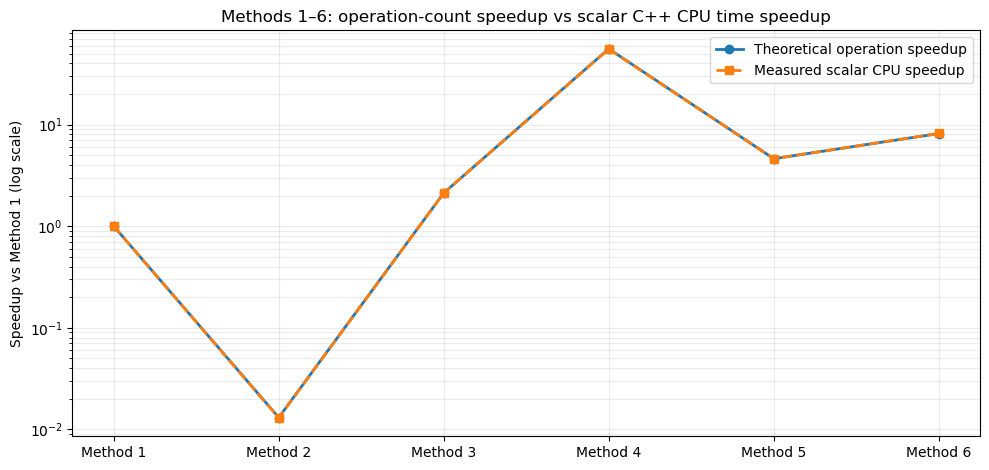

Maximum absolute speedup error: 0.72%
Final scalar sink (prevents dead-code elimination): 4.11517859


In [6]:
import matplotlib.pyplot as plt

x = np.arange(1, 7)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(x, cpu_timing['theoretical_speedup'], 'o-', linewidth=2, label='Theoretical operation speedup')
ax.plot(x, cpu_timing['measured_cpu_speedup'], 's--', linewidth=2, label='Measured scalar CPU speedup')
ax.set_yscale('log')
ax.set_xticks(x, [f'Method {i}' for i in x])
ax.set_ylabel('Speedup vs Method 1 (log scale)')
ax.set_title('Methods 1–6: operation-count speedup vs scalar C++ CPU time speedup')
ax.grid(True, which='both', alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

max_error = cpu_timing['speedup_relative_error_pct'].abs().max()
print(f'Maximum absolute speedup error: {max_error:.2f}%')
print(f'Final scalar sink (prevents dead-code elimination): {scalar_lib.scalar_mac_sink():.8f}')

## LibTorch C++ CPU Classifier Timing

This section uses real batch-one LibTorch C++ inference instead of a synthetic classifier-MAC kernel. Python only defines and exports the six classifier components as TorchScript; every timed `module.forward()` runs inside a compiled C++17 loop. The installed LibTorch CPU backend provides oneDNN, MKL, OpenMP, and AVX-512 acceleration. The front-end and CC portions retain their measured single-thread scalar latency. Model export, loading, optimization, and warm-up are excluded, and the reported classifier latency is the median of three single-thread C++ trials. Methods 5 and 6 execute LR for every sample and add half of the corresponding fine-classifier latency under balanced routing.


LibTorch `2.5.1+cu121` C++ timing used `1` inference thread on CPU core `0`. The component benchmark took `21.63 s`; C++ compilation (`13.34 s`), TorchScript export, model loading/optimization, and warm-up are excluded from latency.

,component,parameters,classifier_MACs,libtorch_threads,repeats_per_trial,trial_1_ms,trial_2_ms,trial_3_ms,libtorch_median_ms,libtorch_mean_ms,benchmark_wall_s,export_s_excluded,checksum
0,CAP8,"1,269,072","34,900,152",1,141,6.643497,6.609998,6.697674,6.643497,6.650390,3.812,0.350,-1.366166
1,Snoap2024_CNN,"2,757,816","7,428,120,704",1,2,521.992123,523.906312,532.130337,523.906312,526.009591,5.518,1.590,0.505563
2,LR55_to_8,448,440,1,10000,0.005807,0.005877,0.005668,0.005807,0.005784,0.961,0.029,-0.059898
3,LR55_to_5,280,275,1,10000,0.006119,0.006252,0.006104,0.006119,0.006158,1.020,0.008,-0.376949
4,CAP4,"1,100,068","29,449,776",1,241,4.210510,4.226363,4.198602,4.210510,4.211825,4.016,0.235,-0.009700
5,CAPNetLite,"111,716","11,199,136",1,1044,0.985346,0.999545,0.982762,0.985346,0.989218,4.022,0.066,-0.163715


,method_id,method,libtorch_threads,front_end_scalar_ms,cc_scalar_ms,classifier_scalar_ms,classifier_libtorch_ms,scalar_total_ms,libtorch_total_ms,classifier_libtorch_gain,overall_libtorch_gain,libtorch_speedup_vs_method_1
0,1,1. CC-trained CAP,1,20.760494,3.554176,13.665847,6.643497,37.980517,30.958167,2.057×,1.227×,1.0000×
1,2,2. I/Q–BOI–USP,1,0.878841,0.000000,2929.748428,523.906312,2930.627269,524.785153,5.592×,5.584×,0.0590×
2,3,3. Full Eight-Class FFT–CC–CAP,1,0.680421,3.556161,13.673478,6.643497,17.910060,10.880078,2.058×,1.646×,2.8454×
3,4,4. Direct Eight-Class FFT–LR,1,0.684495,0.000000,0.000173,0.005807,0.684668,0.690302,0.030×,0.992×,44.8473×
4,5,5. Hierarchical FFT–LR/CC–CAP,1,0.679344,1.775267,5.760021,2.111373,8.214632,4.565984,2.728×,1.799×,6.7802×
5,6,6. Hierarchical FFT–LR/CC–CAPNetLite,1,0.678901,1.774109,2.189054,0.498792,4.642064,2.951802,4.389×,1.573×,10.4879×


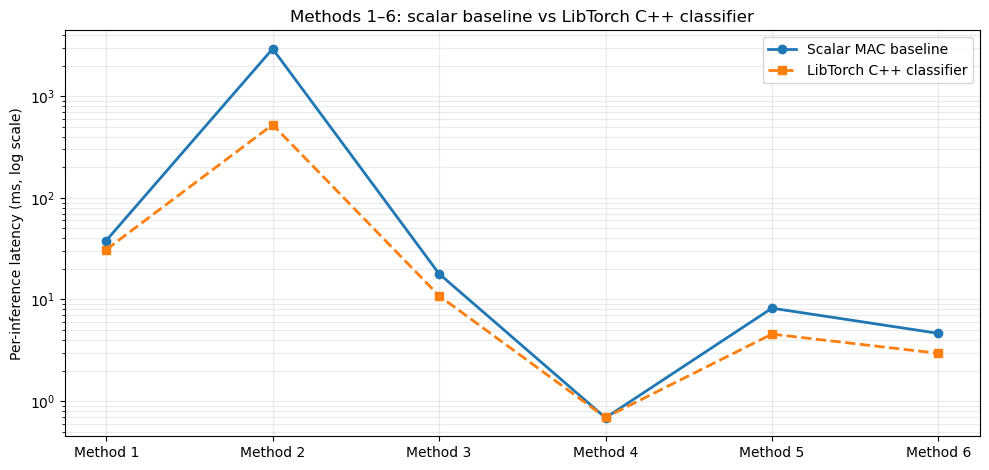

In [7]:
# Export the actual classifiers to TorchScript and benchmark module.forward() in C++.
import json
import torch
import torch.nn as nn
import torch.nn.functional as F

LIBTORCH_THREADS = 1
LIBTORCH_TARGET_MEASURED_MS = 1_000.0
LIBTORCH_MAX_REPEATS = 10_000
LIBTORCH_TRIALS = 3
LIBTORCH_SEED = 0x20260807

# Keep Python-side tracing on one CPU thread as well; timed inference runs in the pinned C++ process below.
torch.set_num_threads(LIBTORCH_THREADS)
if torch.get_num_interop_threads() != 1:
    try:
        torch.set_num_interop_threads(1)
    except RuntimeError:
        pass

torch.manual_seed(LIBTORCH_SEED)
rng = np.random.default_rng(LIBTORCH_SEED)


class FixedSameConv2d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, stride, pad, bias):
        super().__init__()
        self.pad = pad
        self.conv = nn.Conv2d(
            in_ch, out_ch, kernel_size=kernel_size, stride=stride, padding=0, bias=bias
        )

    def forward(self, x):
        return self.conv(F.pad(x, self.pad))


class CAPBranchCpp(nn.Module):
    def __init__(self, in_ch, c1, c2, fc_mid, conv_bias, fc1_bias):
        super().__init__()
        self.conv1 = FixedSameConv2d(
            in_ch, c1, kernel_size=(4, 4), stride=(1, 2),
            pad=(1, 1, 1, 2), bias=conv_bias,
        )
        self.bn1 = nn.BatchNorm2d(c1)
        self.conv2 = FixedSameConv2d(
            c1, c2, kernel_size=(4, 6), stride=(1, 2),
            pad=(2, 2, 1, 2), bias=conv_bias,
        )
        self.bn2 = nn.BatchNorm2d(c2)
        self.pool = nn.AdaptiveAvgPool2d((11, 2))
        self.fc1 = nn.Linear(11 * 2 * c2, fc_mid, bias=fc1_bias)
        self.bn3 = nn.BatchNorm1d(fc_mid)
        self.fc2 = nn.Linear(fc_mid, 1, bias=True)

    def forward(self, x):
        x = torch.tanh(self.bn1(self.conv1(x)))
        x = torch.tanh(self.bn2(self.conv2(x)))
        x = self.pool(x).flatten(1)
        x = F.relu(self.bn3(self.fc1(x)))
        return self.fc2(x)


class CAPNetworkCpp(nn.Module):
    def __init__(self, n_classes, shared_ch, branch_c1, branch_c2, branch_fc,
                 conv_bias=False, fc1_bias=False):
        super().__init__()
        self.shared = FixedSameConv2d(
            1, shared_ch, kernel_size=(6, 4), stride=(1, 2),
            pad=(1, 2, 2, 3), bias=conv_bias,
        )
        self.shared_bn = nn.BatchNorm2d(shared_ch)
        self.branches = nn.ModuleList([
            CAPBranchCpp(
                shared_ch, branch_c1, branch_c2, branch_fc, conv_bias, fc1_bias
            )
            for _ in range(n_classes)
        ])

    def forward(self, x):
        x = torch.tanh(self.shared_bn(self.shared(x)))
        return torch.cat([branch(x) for branch in self.branches], dim=1)


class USPBranchCpp(nn.Module):
    def __init__(self, input_channels):
        super().__init__()
        layers = []
        in_ch = input_channels
        channels = (16, 24, 32, 48, 64, 96)
        for layer_index, out_ch in enumerate(channels):
            layers.extend([
                nn.Conv1d(in_ch, out_ch, kernel_size=23, padding=11, bias=False),
                nn.BatchNorm1d(out_ch),
                nn.ReLU(),
            ])
            if layer_index < 5:
                layers.append(nn.MaxPool1d(kernel_size=2, stride=2))
            in_ch = out_ch
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(96, 8, bias=True)

    def forward(self, x):
        return self.fc(self.pool(self.features(x)).squeeze(-1))


class Snoap2024CNNCpp(nn.Module):
    INPUT_CHANNELS = (2, 1, 2, 1, 2, 2, 1, 2, 1, 2)

    def __init__(self):
        super().__init__()
        self.branches = nn.ModuleList([
            USPBranchCpp(input_channels) for input_channels in self.INPUT_CHANNELS
        ])
        self.fc = nn.Linear(10 * 8, 8, bias=True)

    def forward(self, packed_input):
        inputs = torch.split(packed_input, self.INPUT_CHANNELS, dim=1)
        return self.fc(torch.cat([
            branch(x) for branch, x in zip(self.branches, inputs)
        ], dim=1))


class ResBlockCpp(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        residual = x
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))
        return F.relu(x + residual)


class CAPNetLiteCpp(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Conv2d(1, 32, 3, padding=1, bias=False)
        self.stem_bn = nn.BatchNorm2d(32)
        self.block1 = ResBlockCpp(32)
        self.down = nn.Conv2d(32, 64, 3, stride=(1, 2), padding=1, bias=False)
        self.down_bn = nn.BatchNorm2d(64)
        self.block2 = ResBlockCpp(64)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(64, 4)

    def forward(self, x):
        x = F.relu(self.stem_bn(self.stem(x)))
        x = self.block1(x)
        x = F.relu(self.down_bn(self.down(x)))
        x = self.block2(x)
        return self.fc(self.pool(x).flatten(1))


def trainable_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters())


cap8_model = CAPNetworkCpp(
    n_classes=8, shared_ch=56, branch_c1=56, branch_c2=72, branch_fc=7,
    conv_bias=True, fc1_bias=True,
)
snoap_model = Snoap2024CNNCpp()
lr8_model = nn.Linear(55, 8)
lr5_model = nn.Linear(55, 5)
cap4_model = CAPNetworkCpp(
    n_classes=4, shared_ch=72, branch_c1=72, branch_c2=96, branch_fc=12,
    conv_bias=False, fc1_bias=False,
)
capnetlite_model = CAPNetLiteCpp()

classifier_specs = {
    'CAP8': {
        'model': cap8_model,
        'input': torch.from_numpy(rng.standard_normal((1, 1, 11, 15), dtype=np.float32)),
        'parameters': 1_269_072,
        'MACs': int(CAP8_MACS),
    },
    'Snoap2024_CNN': {
        'model': snoap_model,
        'input': torch.from_numpy(rng.standard_normal((1, 16, N), dtype=np.float32)),
        'parameters': 2_757_816,
        'MACs': int(SNOAP_CNN_MACS),
    },
    'LR55_to_8': {
        'model': lr8_model,
        'input': torch.from_numpy(rng.standard_normal((1, 55), dtype=np.float32)),
        'parameters': 448,
        'MACs': int(LR8_MACS),
    },
    'LR55_to_5': {
        'model': lr5_model,
        'input': torch.from_numpy(rng.standard_normal((1, 55), dtype=np.float32)),
        'parameters': 280,
        'MACs': int(LR5_MACS),
    },
    'CAP4': {
        'model': cap4_model,
        'input': torch.from_numpy(rng.standard_normal((1, 1, 11, 15), dtype=np.float32)),
        'parameters': 1_100_068,
        'MACs': int(CAP4_MACS),
    },
    'CAPNetLite': {
        'model': capnetlite_model,
        'input': torch.from_numpy(rng.standard_normal((1, 1, 11, 15), dtype=np.float32)),
        'parameters': 111_716,
        'MACs': int(CAPNETLITE_MACS),
    },
}

for component_name, spec in classifier_specs.items():
    actual_parameters = trainable_parameters(spec['model'])
    assert actual_parameters == spec['parameters'], (
        component_name, actual_parameters, spec['parameters']
    )
    spec['model'].eval()

TORCH_ROOT = Path(torch.__file__).resolve().parent
LIBTORCH_CPP_SOURCE = BASE_DIR / 'helper/cpp/libtorch_classifier_benchmark.cpp'
LIBTORCH_CPP_BINARY = CPP_BUILD_DIR / 'libtorch_classifier_benchmark'
LIBTORCH_MODEL_DIR = CPP_BUILD_DIR / 'libtorch_classifier_models'
LIBTORCH_MODEL_DIR.mkdir(parents=True, exist_ok=True)

LIBTORCH_CPP_FLAGS = [
    '-O3', '-std=c++17',
    f'-D_GLIBCXX_USE_CXX11_ABI={int(torch._C._GLIBCXX_USE_CXX11_ABI)}',
    f'-I{TORCH_ROOT / "include"}',
    f'-I{TORCH_ROOT / "include/torch/csrc/api/include"}',
]
LIBTORCH_LINK_FLAGS = [
    f'-L{TORCH_ROOT / "lib"}',
    f'-Wl,-rpath,{TORCH_ROOT / "lib"}',
    '-ltorch', '-ltorch_cpu', '-lc10', '-lpthread',
]
libtorch_compile_command = [
    'g++', *LIBTORCH_CPP_FLAGS, str(LIBTORCH_CPP_SOURCE),
    *LIBTORCH_LINK_FLAGS, '-o', str(LIBTORCH_CPP_BINARY),
]
libtorch_compile_t0 = time.perf_counter()
subprocess.run(libtorch_compile_command, check=True, capture_output=True, text=True)
libtorch_compile_s_excluded = time.perf_counter() - libtorch_compile_t0

libtorch_environment = os.environ.copy()
libtorch_environment.update({
    'OMP_NUM_THREADS': str(LIBTORCH_THREADS),
    'MKL_NUM_THREADS': str(LIBTORCH_THREADS),
    'OPENBLAS_NUM_THREADS': str(LIBTORCH_THREADS),
    'OMP_DYNAMIC': 'FALSE',
})
libtorch_affinity = os.sched_getaffinity(0) if hasattr(os, 'sched_getaffinity') else None
libtorch_benchmark_core = min(libtorch_affinity) if libtorch_affinity else -1

component_rows = []
libtorch_benchmark_t0 = time.perf_counter()
for component_name, spec in classifier_specs.items():
    model_path = LIBTORCH_MODEL_DIR / f'{component_name}.pt'
    export_t0 = time.perf_counter()
    with torch.inference_mode():
        traced_model = torch.jit.trace(
            spec['model'], spec['input'], check_trace=False, strict=False
        )
    traced_model.save(str(model_path))
    export_s_excluded = time.perf_counter() - export_t0

    input_shape = ','.join(str(dimension) for dimension in spec['input'].shape)
    warmups = 1 if spec['MACs'] >= 1_000_000_000 else 3
    command = [
        str(LIBTORCH_CPP_BINARY), str(model_path), input_shape,
        str(LIBTORCH_THREADS), str(libtorch_benchmark_core), str(warmups),
        str(LIBTORCH_TARGET_MEASURED_MS), str(LIBTORCH_MAX_REPEATS),
        str(LIBTORCH_TRIALS),
    ]
    benchmark_t0 = time.perf_counter()
    completed = subprocess.run(
        command, check=True, capture_output=True, text=True, env=libtorch_environment
    )
    benchmark_wall_s = time.perf_counter() - benchmark_t0
    output_lines = [line for line in completed.stdout.splitlines() if line.strip()]
    timing = json.loads(output_lines[-1])
    component_rows.append({
        'component': component_name,
        'parameters': spec['parameters'],
        'classifier_MACs': spec['MACs'],
        'libtorch_threads': LIBTORCH_THREADS,
        'repeats_per_trial': timing['repeats'],
        'trial_1_ms': timing['trial_ms'][0],
        'trial_2_ms': timing['trial_ms'][1],
        'trial_3_ms': timing['trial_ms'][2],
        'libtorch_median_ms': timing['median_ms'],
        'libtorch_mean_ms': timing['mean_ms'],
        'benchmark_wall_s': benchmark_wall_s,
        'export_s_excluded': export_s_excluded,
        'checksum': timing['checksum'],
    })

libtorch_benchmark_wall_s = time.perf_counter() - libtorch_benchmark_t0
libtorch_components = pd.DataFrame(component_rows)
libtorch_component_ms = libtorch_components.set_index('component')['libtorch_median_ms']

classifier_libtorch_ms = np.array([
    libtorch_component_ms['CAP8'],
    libtorch_component_ms['Snoap2024_CNN'],
    libtorch_component_ms['CAP8'],
    libtorch_component_ms['LR55_to_8'],
    libtorch_component_ms['LR55_to_5'] + 0.5 * libtorch_component_ms['CAP4'],
    libtorch_component_ms['LR55_to_5'] + 0.5 * libtorch_component_ms['CAPNetLite'],
], dtype=np.float64)

libtorch_timing = cpu_timing[[
    'method_id', 'method', 'front_end_ms', 'cc_ms', 'classifier_ms', 'per_inference_cpu_ms'
]].copy()
libtorch_timing = libtorch_timing.rename(columns={
    'front_end_ms': 'front_end_scalar_ms',
    'cc_ms': 'cc_scalar_ms',
    'classifier_ms': 'classifier_scalar_ms',
    'per_inference_cpu_ms': 'scalar_total_ms',
})
libtorch_timing['libtorch_threads'] = LIBTORCH_THREADS
libtorch_timing['classifier_libtorch_ms'] = classifier_libtorch_ms
libtorch_timing['libtorch_total_ms'] = (
    libtorch_timing['front_end_scalar_ms']
    + libtorch_timing['cc_scalar_ms']
    + libtorch_timing['classifier_libtorch_ms']
)
libtorch_timing['classifier_libtorch_gain'] = (
    libtorch_timing['classifier_scalar_ms'] / libtorch_timing['classifier_libtorch_ms']
)
libtorch_timing['overall_libtorch_gain'] = (
    libtorch_timing['scalar_total_ms'] / libtorch_timing['libtorch_total_ms']
)
libtorch_reference_ms = float(libtorch_timing.loc[0, 'libtorch_total_ms'])
libtorch_timing['libtorch_speedup_vs_method_1'] = (
    libtorch_reference_ms / libtorch_timing['libtorch_total_ms']
)

display(Markdown(
    f'LibTorch `{torch.__version__}` C++ timing used `{LIBTORCH_THREADS}` inference thread on '
    f'CPU core `{libtorch_benchmark_core}`. The component benchmark took '
    f'`{libtorch_benchmark_wall_s:.2f} s`; C++ compilation (`{libtorch_compile_s_excluded:.2f} s`), '
    'TorchScript export, model loading/optimization, and warm-up are excluded from latency.'
))
display(libtorch_components.style.format({
    'parameters': '{:,.0f}', 'classifier_MACs': '{:,.0f}',
    'trial_1_ms': '{:.6f}', 'trial_2_ms': '{:.6f}', 'trial_3_ms': '{:.6f}',
    'libtorch_median_ms': '{:.6f}', 'libtorch_mean_ms': '{:.6f}',
    'benchmark_wall_s': '{:.3f}', 'export_s_excluded': '{:.3f}',
    'checksum': '{:.6f}',
}))
display(libtorch_timing[[
    'method_id', 'method', 'libtorch_threads',
    'front_end_scalar_ms', 'cc_scalar_ms',
    'classifier_scalar_ms', 'classifier_libtorch_ms',
    'scalar_total_ms', 'libtorch_total_ms',
    'classifier_libtorch_gain', 'overall_libtorch_gain',
    'libtorch_speedup_vs_method_1',
]].style.format({
    'front_end_scalar_ms': '{:.6f}', 'cc_scalar_ms': '{:.6f}',
    'classifier_scalar_ms': '{:.6f}', 'classifier_libtorch_ms': '{:.6f}',
    'scalar_total_ms': '{:.6f}', 'libtorch_total_ms': '{:.6f}',
    'classifier_libtorch_gain': '{:.3f}×', 'overall_libtorch_gain': '{:.3f}×',
    'libtorch_speedup_vs_method_1': '{:.4f}×',
}))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(x, libtorch_timing['scalar_total_ms'], 'o-', linewidth=2, label='Scalar MAC baseline')
ax.plot(x, libtorch_timing['libtorch_total_ms'], 's--', linewidth=2, label='LibTorch C++ classifier')
ax.set_yscale('log')
ax.set_xticks(x, [f'Method {i}' for i in x])
ax.set_ylabel('Per-inference latency (ms, log scale)')
ax.set_title('Methods 1–6: scalar baseline vs LibTorch C++ classifier')
ax.grid(True, which='both', alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()


## Method 6 Route-Level Analysis: Hierarchical FFT–LR/CC–CAPNetLite

The non-QPSK-like route executes the scalar FFT front end and the LibTorch C++ LR55 router. The QPSK-like route additionally executes the full scalar CC preprocessing and the LibTorch C++ CAPNetLite classifier. The final row reports the balanced-routing expectation, and all CPU speedups use the corresponding LibTorch-enhanced Method 1 latency as the baseline.


In [8]:
# Split Method 6 into its two actual routes and recover the balanced expectation.
method1_stage = stage_ops.loc[stage_ops['method_id'] == 1].iloc[0]
method6_stage = stage_ops.loc[stage_ops['method_id'] == 6].iloc[0]
method6_cpu = cpu_timing.loc[cpu_timing['method_id'] == 6].iloc[0]
method6_libtorch = libtorch_timing.loc[libtorch_timing['method_id'] == 6].iloc[0]

baseline_ops = int(method1_stage['total_ops'])
baseline_libtorch_ms = float(libtorch_timing.loc[
    libtorch_timing['method_id'] == 1, 'libtorch_total_ms'
].iloc[0])
fft_front_end_ms = float(method6_cpu['front_end_ms'])
full_cc_ms = 2.0 * float(method6_cpu['cc_ms'])
lr55_libtorch_ms = float(libtorch_component_ms['LR55_to_5'])
capnetlite_libtorch_ms = float(libtorch_component_ms['CAPNetLite'])

route_rows = [
    {
        'route': 'Non-QPSK-like: FFT + LR55',
        'routing_probability': '50%',
        'FFT_front_end_ops': int(front_fft3),
        'CC_ops': 0,
        'LR55_ops': int(LR5_MACS),
        'CAPNetLite_ops': 0,
        'LibTorch_CPU_time_ms': fft_front_end_ms + lr55_libtorch_ms,
    },
    {
        'route': 'QPSK-like: FFT + LR55 + CC + CAPNetLite',
        'routing_probability': '50%',
        'FFT_front_end_ops': int(front_fft3),
        'CC_ops': int(cc_processing),
        'LR55_ops': int(LR5_MACS),
        'CAPNetLite_ops': int(CAPNETLITE_MACS),
        'LibTorch_CPU_time_ms': (
            fft_front_end_ms + full_cc_ms + lr55_libtorch_ms + capnetlite_libtorch_ms
        ),
    },
]
route_breakdown = pd.DataFrame(route_rows)
route_breakdown['pre_processing_ops'] = (
    route_breakdown['FFT_front_end_ops'] + route_breakdown['CC_ops']
)
route_breakdown['classifier_ops'] = (
    route_breakdown['LR55_ops'] + route_breakdown['CAPNetLite_ops']
)
route_breakdown['total_ops'] = (
    route_breakdown['pre_processing_ops'] + route_breakdown['classifier_ops']
)
route_breakdown['operation_speedup_vs_method_1'] = baseline_ops / route_breakdown['total_ops']
route_breakdown['LibTorch_CPU_speedup_vs_method_1'] = (
    baseline_libtorch_ms / route_breakdown['LibTorch_CPU_time_ms']
)

expected_values = {
    column: int((route_breakdown[column] * 0.5).sum())
    for column in [
        'FFT_front_end_ops', 'CC_ops', 'LR55_ops', 'CAPNetLite_ops',
        'pre_processing_ops', 'classifier_ops', 'total_ops',
    ]
}
expected_libtorch_ms = float((route_breakdown['LibTorch_CPU_time_ms'] * 0.5).sum())
expected_row = {
    'route': 'Expected (balanced routing)',
    'routing_probability': '50% / 50%',
    **expected_values,
    'LibTorch_CPU_time_ms': expected_libtorch_ms,
    'operation_speedup_vs_method_1': baseline_ops / expected_values['total_ops'],
    'LibTorch_CPU_speedup_vs_method_1': baseline_libtorch_ms / expected_libtorch_ms,
}
method6_route_analysis = pd.concat(
    [route_breakdown, pd.DataFrame([expected_row])], ignore_index=True
)

# The path-weighted result must reproduce the existing operation totals and LibTorch aggregate.
assert expected_values['pre_processing_ops'] == int(method6_stage['front_end_ops'] + method6_stage['cc_ops'])
assert expected_values['classifier_ops'] == int(method6_stage['classifier_ops'])
assert expected_values['total_ops'] == int(method6_stage['total_ops'])
assert np.isclose(expected_libtorch_ms, float(method6_libtorch['libtorch_total_ms']))
assert np.isclose(expected_row['operation_speedup_vs_method_1'], speedup_with_classifier[5])
assert np.isclose(
    expected_row['LibTorch_CPU_speedup_vs_method_1'],
    float(method6_libtorch['libtorch_speedup_vs_method_1']),
)

display(method6_route_analysis.style.format({
    'FFT_front_end_ops': '{:,.0f}', 'CC_ops': '{:,.0f}',
    'LR55_ops': '{:,.0f}', 'CAPNetLite_ops': '{:,.0f}',
    'pre_processing_ops': '{:,.0f}', 'classifier_ops': '{:,.0f}',
    'total_ops': '{:,.0f}', 'LibTorch_CPU_time_ms': '{:.6f}',
    'operation_speedup_vs_method_1': '{:.4f}×',
    'LibTorch_CPU_speedup_vs_method_1': '{:.4f}×',
}))

print(
    f"Expected Method 6: {expected_values['total_ops']:,} operations, "
    f"{expected_libtorch_ms:.6f} ms LibTorch-enhanced CPU time, "
    f"{expected_row['operation_speedup_vs_method_1']:.4f}x operation speedup, "
    f"{expected_row['LibTorch_CPU_speedup_vs_method_1']:.4f}x CPU speedup."
)


,route,routing_probability,FFT_front_end_ops,CC_ops,LR55_ops,CAPNetLite_ops,LibTorch_CPU_time_ms,pre_processing_ops,classifier_ops,total_ops,operation_speedup_vs_method_1,LibTorch_CPU_speedup_vs_method_1
0,Non-QPSK-like: FFT + LR55,50%,"1,736,704",0,275,0,0.685019,"1,736,704",275,"1,736,979",55.8415×,45.1931×
1,QPSK-like: FFT + LR55 + CC + CAPNetLite,50%,"1,736,704","9,076,736",275,"11,199,136",5.218584,"10,813,440","11,199,411","22,012,851",4.4063×,5.9323×
2,Expected (balanced routing),50% / 50%,"1,736,704","4,538,368",275,"5,599,568",2.951802,"6,275,072","5,599,843","11,874,915",8.1681×,10.4879×


Expected Method 6: 11,874,915 operations, 2.951802 ms LibTorch-enhanced CPU time, 8.1681x operation speedup, 10.4879x CPU speedup.
